# TP 2 — Deep Learning : du pipeline ML au réseau de neurones

**Cours NLP et Transformers — CY Tech**

---

## Objectif

Reprendre **exactement la tâche du TP 1** (« qui parle ? » : 5 locuteurs de *Tiny Shakespeare*, répliques d'au moins 5 mots, même découpage train/test) et la traiter avec des **réseaux de neurones**, puis **comparer honnêtement ML et DL**.

`texte brut → prétraitement → représentation → modèle (ML ou DL) → évaluation`

Le but n'est pas de « battre » le TP 1 à tout prix : c'est de savoir **quand** le deep learning apporte quelque chose, et de pouvoir le **mesurer**.

## Ce qui change par rapport au TP 1

| | TP 1 (ML) | TP 2 (DL) |
|---|---|---|
| Représentation | TF–IDF figé | + **embeddings appris** avec le modèle |
| Modèle | solution convexe, déterministe | réseau entraîné par descente de gradient : **stochastique**, sensible aux hyperparamètres |
| Réglage | peu d'hyperparamètres | nombre d'epochs, taux d'apprentissage, dropout... → il faut un **jeu de validation** |
| Mesure | un score | une **moyenne sur plusieurs graines** + incertitude |

## Protocole (ce qui rend les scores crédibles)

1. **Même test qu'au TP 1** (153 répliques) : utilisé **une seule fois**, pour la mesure finale.
2. Un **jeu de validation** est prélevé *dans le train* pour choisir le nombre d'epochs (early stopping).
3. Vocabulaire, IDF et longueur maximale sont **ajustés sur le train uniquement** (jamais sur validation ni test).
4. Chaque réseau est entraîné avec **5 graines** ; on rapporte moyenne ± écart-type.
5. Les modèles sont comparés à la **baseline** et aux **modèles ML du TP 1**, avec un intervalle de confiance par bootstrap.

---

## 0. Environnement

PyTorch est déjà installé dans Colab. Le CPU suffit : le jeu fait ~600 exemples.

In [1]:
import re, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
SEEDS = [0, 1, 2, 3, 4]           # le DL est stochastique : on répète l'entraînement
torch.set_num_threads(2)
DEVICE = "cpu"                    # les données sont minuscules : le CPU suffit
np.random.seed(RANDOM_STATE)

def fixer_graine(s):
    np.random.seed(s); torch.manual_seed(s)

print("PyTorch", torch.__version__, "| device :", DEVICE)

PyTorch 2.14.1+cu130 | device : cpu


## 1. Reconstruire la tâche du TP 1

On réutilise le parsing du TP 1, la sélection des 5 locuteurs les plus fréquents, le seuil de 5 mots et **le même découpage** (`random_state=42`). Les scores du TP 1 sont donc directement comparables.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")

def parser_repliques(txt):
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({"locuteur": entete.group(1).strip(),
                           "replique": " ".join(p.strip() for p in parties[1:]).strip()})
    return pd.DataFrame(lignes)

df = parser_repliques(texte)
df["nb_mots"] = df["replique"].str.split().str.len()

# MÊME tâche et MÊME découpage que le TP 1 -> les scores sont directement comparables
N_LOCUTEURS, SEUIL_MOTS = 5, 5
top = df["locuteur"].value_counts().head(N_LOCUTEURS).index
donnees = df[df["locuteur"].isin(top) & (df["nb_mots"] >= SEUIL_MOTS)][["replique", "locuteur"]].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"], donnees["locuteur"], test_size=0.2,
    stratify=donnees["locuteur"], random_state=RANDOM_STATE)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

CLASSES = sorted(y_train.unique())
c2i = {c: i for i, c in enumerate(CLASSES)}
ytr_i = y_train.map(c2i).values
yte_i = y_test.map(c2i).values

print(f"{len(donnees)} exemples | train {len(X_train)} | test {len(X_test)}  (identique au TP 1)")
print(CLASSES)

761 exemples | train 608 | test 153  (identique au TP 1)
['DUKE VINCENTIO', 'GLOUCESTER', 'MENENIUS', 'PETRUCHIO', 'ROMEO']


## 2. Nettoyage et prétraitement

### 2.1 Un jeu de validation à l'intérieur du train

Un réseau de neurones s'entraîne epoch après epoch : à partir d'un moment il **mémorise** le train. Il faut un jeu de validation pour savoir *quand s'arrêter*. On le prélève dans le train ; **le test n'est jamais utilisé pour cela**.

In [3]:
# Jeu de VALIDATION pris à l'intérieur du train : il sert à choisir le nombre d'epochs (early stopping).
# Le test n'est utilisé qu'une seule fois, pour la mesure finale.
idx_sub, idx_val = train_test_split(np.arange(len(X_train)), test_size=0.2, stratify=ytr_i, random_state=RANDOM_STATE)
print(f"train_sub : {len(idx_sub)} | validation : {len(idx_val)} | test : {len(X_test)}")

train_sub : 486 | validation : 122 | test : 153


### 2.2 Tokenisation, vocabulaire, longueur maximale

Un réseau ne lit pas du texte : il lit des **indices**. Chaîne de prétraitement : minuscules → découpage en mots (`[a-z']+`, l'apostrophe est conservée : *o'*, *'tis*) → vocabulaire → indices → **padding** à une longueur fixe.

Choix à justifier :
- **`min_freq=2`** : un mot vu une seule fois dans le train n'a pas d'embedding appris de façon fiable ; il devient `<unk>`.
- **longueur max = percentile 95** des longueurs du train : au-delà, on tronque (quelques tirades de plus de 500 mots feraient un tenseur énorme rempli de zéros).
- Tout (vocabulaire, IDF, longueur max) est **ajusté sur le train**, via la classe `Encodeur`.

In [4]:
TOKEN_RE = re.compile(r"[a-z']+")
def tokeniser(t):
    return TOKEN_RE.findall(t.lower())

class Encodeur:
    """Tout ce qui APPREND quelque chose (vocabulaire, IDF, longueur max) est ajusté sur les textes fournis à fit()."""
    def __init__(self, min_freq=2, pct_long=95, long_max=120):
        self.min_freq, self.pct_long, self.long_max = min_freq, pct_long, long_max

    def fit(self, textes):
        from collections import Counter
        toks = [tokeniser(t) for t in textes]
        cnt = Counter(w for t in toks for w in t)
        self.itos = ["<pad>", "<unk>"] + sorted(w for w, c in cnt.items() if c >= self.min_freq)
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.max_len = int(min(self.long_max, np.percentile([len(t) for t in toks], self.pct_long)))
        self.tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(list(textes))
        return self

    def ids(self, textes):
        seqs = [[self.stoi.get(w, 1) for w in tokeniser(t)][: self.max_len] or [1] for t in textes]
        lens = torch.tensor([len(s) for s in seqs])
        X = torch.zeros(len(seqs), self.max_len, dtype=torch.long)
        for i, s in enumerate(seqs):
            X[i, : len(s)] = torch.tensor(s)
        return X, lens

    def matrice_tfidf(self, textes):
        return torch.tensor(self.tfidf.transform(list(textes)).toarray(), dtype=torch.float32)

enc = Encodeur().fit(X_train)       # ajusté sur le train UNIQUEMENT
lg = np.array([len(tokeniser(t)) for t in X_train])
print(f"Vocabulaire (min_freq=2) : {len(enc.itos):,} tokens | longueur max retenue : {enc.max_len} tokens")
print(f"Longueur des textes d'entraînement (tokens) : médiane {np.median(lg):.0f}, p95 {np.percentile(lg, 95):.0f}, max {lg.max()}")
print(f"Textes tronqués : {(lg > enc.max_len).mean():.1%}")

toks_test = [w for t in X_test for w in tokeniser(t)]
oov = np.mean([w not in enc.stoi for w in toks_test])
print(f"Tokens du TEST hors vocabulaire (-> <unk>) : {oov:.1%}")

exemple = X_train[3]
print("\nExemple :", exemple[:90], "...")
print("Tokens  :", tokeniser(exemple)[:10])
print("Indices :", enc.ids([exemple])[0][0][:10].tolist())

Vocabulaire (min_freq=2) : 1,583 tokens | longueur max retenue : 112 tokens
Longueur des textes d'entraînement (tokens) : médiane 18, p95 112, max 581
Textes tronqués : 4.9%
Tokens du TEST hors vocabulaire (-> <unk>) : 15.6%

Exemple : Down with that sword! Tribunes, withdraw awhile. ...
Tokens  : ['down', 'with', 'that', 'sword', 'tribunes', 'withdraw', 'awhile']
Indices : [376, 1526, 1325, 1306, 1392, 1528, 93, 0, 0, 0]


**Questions et réponses**

1. **Pourquoi construire vocabulaire, IDF et longueur maximale sur le train uniquement ?** Ce sont des paramètres *appris* à partir des données (quels mots existent, dans combien de documents ils apparaissent, quelle longueur est « normale »). Les calculer avec le test, ou même avec la validation, ferait remonter de l'information du test vers l'entraînement : exactement la fuite de données du TP 1. D'où deux `Encodeur` : un ajusté sur `train_sub` pour la phase de validation, un autre sur tout le train pour le modèle final.
2. **Que montrent les chiffres ?**
   - Vocabulaire de **1 583 tokens** (min_freq = 2) ; les 3 464 colonnes du TF–IDF sont plus nombreuses car elles incluent les bigrammes.
   - Longueur médiane de **18 tokens**, 95ᵉ percentile à **112** : retenu comme longueur maximale, **4,9 % des textes sont tronqués**. Choisir le maximum (581) aurait produit, pour une réplique médiane, des tenseurs remplis à ≈ 97 % de padding.
   - **15,6 % des tokens du test sont hors vocabulaire** (`<unk>`). Pour un réseau à embeddings appris, ces mots sont invisibles : c'est la limite principale des embeddings entraînés sur 608 répliques (un embedding **pré-entraîné** couvrirait la plupart de ces mots, c'est tout l'intérêt du cours suivant).
3. **Pourquoi le padding pose-t-il problème aux RNN ?** Un GRU lit la séquence de gauche à droite (et de droite à gauche pour le sens inverse) : s'il lisait les zéros de padding, l'état final serait pollué. On utilise donc `pack_padded_sequence`, qui s'arrête à la vraie longueur de chaque réplique.

## 3. Représentation

Deux familles, un même texte :

| | Représentation | Ce que le modèle voit |
|---|---|---|
| **A. Creuse** | TF–IDF (1-2 grammes), vecteur de ~3 500 dimensions | un *sac de mots* pondéré : aucun ordre |
| **B. Dense apprise** | indices de tokens → **matrice d'embeddings** `E ∈ ℝ^{|V|×d}` | une *séquence* de vecteurs denses de dimension 64, ajustés par rétropropagation |

La représentation B n'est **pas pré-entraînée** ici : les embeddings sont appris à partir de 608 répliques seulement (voir les limites en conclusion).

## 4. Comparaison entre modèles ML et DL

### 4.1 Les modèles ML du TP 1 (même split, même représentation TF–IDF)

In [5]:
# Modèles ML du TP 1, réentraînés sur le même split (même représentation TF-IDF)
Xtr_t = enc.tfidf.transform(X_train); Xte_t = enc.tfidf.transform(X_test)
modeles_ml = {
    "Baseline (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "ML · Naive Bayes": MultinomialNB(alpha=0.1),
    "ML · Régression logistique": LogisticRegression(C=10, class_weight="balanced", max_iter=2000),
    "ML · LinearSVC": LinearSVC(class_weight="balanced"),
}
pred_ml = {}
for nom, m in modeles_ml.items():
    pred_ml[nom] = m.fit(Xtr_t, ytr_i).predict(Xte_t)
    print(f"{nom:32s} accuracy = {accuracy_score(yte_i, pred_ml[nom]):.3f} | F1 macro = {f1_score(yte_i, pred_ml[nom], average='macro'):.3f}")

Baseline (classe majoritaire)    accuracy = 0.261 | F1 macro = 0.083
ML · Naive Bayes                 accuracy = 0.686 | F1 macro = 0.686


ML · Régression logistique       accuracy = 0.660 | F1 macro = 0.663
ML · LinearSVC                   accuracy = 0.647 | F1 macro = 0.649


### 4.2 Les réseaux de neurones

| Modèle | Idée | Cours |
|---|---|---|
| **MLP (TF-IDF)** | une couche cachée de 128 neurones ReLU + dropout sur le vecteur TF–IDF | neurone, MLP |
| **Embeddings + moyenne** | embedding de chaque mot, **moyenne** des vecteurs, couche linéaire (type fastText) | embeddings |
| **BiGRU** | embeddings → GRU bidirectionnel ; l'état final dans les deux sens résume la réplique | RNN, GRU |
| **BiLSTM** | idem avec un LSTM | RNN, LSTM |

Ingrédients communs : **entropie croisée pondérée** par classe (équivalent de `class_weight='balanced'` du TP 1), **Adam**, **dropout**, **weight decay**, **gradient clipping** (le cours explique pourquoi : gradients qui explosent dans les RNN), **early stopping**.

In [6]:
class MLP(nn.Module):
    """Perceptron multicouche sur TF-IDF : tout le texte est résumé en un vecteur creux (sac de mots)."""
    def __init__(self, d_in, n_cls, h=128, p=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, n_cls))
    def forward(self, x, lens=None):
        return self.net(x)

class EmbMoyenne(nn.Module):
    """Embeddings appris + moyenne des vecteurs de mots (type fastText) : ordre des mots ignoré."""
    def __init__(self, vocab, n_cls, d=64, p=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=0)
        self.drop, self.fc = nn.Dropout(p), nn.Linear(d, n_cls)
    def forward(self, ids, lens):
        e = self.emb(ids) * (ids != 0).unsqueeze(-1)
        return self.fc(self.drop(e.sum(1) / lens.clamp(min=1).unsqueeze(-1)))

class RNNClf(nn.Module):
    """Embeddings + GRU ou LSTM bidirectionnel ; l'état final (dans les deux sens) résume la réplique."""
    def __init__(self, vocab, n_cls, kind="gru", d=64, h=64, p=0.5, p_emb=0.0):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=0)
        self.drop_emb = nn.Dropout(p_emb)
        Rnn = nn.GRU if kind == "gru" else nn.LSTM
        self.rnn = Rnn(d, h, batch_first=True, bidirectional=True)
        self.kind, self.drop, self.fc = kind, nn.Dropout(p), nn.Linear(2 * h, n_cls)
    def forward(self, ids, lens):
        pk = pack_padded_sequence(self.drop_emb(self.emb(ids)), lens.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(pk)
        h = h[0] if self.kind == "lstm" else h            # LSTM renvoie (h, c)
        return self.fc(self.drop(torch.cat([h[0], h[1]], dim=1)))

# hyperparamètres : valeurs de départ fixées a priori ; ils pourront être affinés SUR LA VALIDATION (jamais sur le test)
HP = {
    "MLP (TF-IDF)":         dict(lr=1e-3, wd=1e-4, h=128, p=0.5),
    "Embeddings + moyenne": dict(lr=5e-3, wd=1e-4, d=64,  p=0.5),
    "BiGRU":                dict(lr=3e-3, wd=1e-4, d=64, h=64, p=0.5, p_emb=0.0),
    "BiLSTM":               dict(lr=3e-3, wd=1e-4, d=64, h=64, p=0.5, p_emb=0.0),
}
NOMS_DL = list(HP)

def construire(nom, enc):
    V, K = len(enc.itos), len(CLASSES)
    hp = {k: v for k, v in HP[nom].items() if k not in ("lr", "wd")}
    if nom == "MLP (TF-IDF)":  return MLP(len(enc.tfidf.vocabulary_), K, **hp)
    if nom == "Embeddings + moyenne": return EmbMoyenne(V, K, **hp)
    if nom == "BiGRU":  return RNNClf(V, K, "gru", **hp)
    if nom == "BiLSTM": return RNNClf(V, K, "lstm", **hp)
for n in NOMS_DL:
    nb_params = sum(p.numel() for p in construire(n, enc).parameters())
    print(f"{n:22s} {nb_params:>9,} paramètres")

MLP (TF-IDF)             444,165 paramètres
Embeddings + moyenne     101,637 paramètres
BiGRU                    151,877 paramètres
BiLSTM                   168,517 paramètres


In [7]:
def entree(nom, enc, textes):
    """Convertit les textes selon ce que le modèle attend (matrice TF-IDF ou indices de tokens)."""
    if nom == "MLP (TF-IDF)":
        return enc.matrice_tfidf(textes), None
    return enc.ids(textes)

def predire(model, X, L, bs=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(X[i:i+bs], None if L is None else L[i:i+bs]))
    return torch.cat(out)

def poids_classes(y):
    n = np.bincount(y, minlength=len(CLASSES)); return torch.tensor(len(y) / (len(CLASSES) * n), dtype=torch.float32)

def entrainer(nom, enc, Xtr_txt, ytr, seed, val=None, epochs_max=80, patience=10, n_epochs=None, bs=32):
    """val=(textes, y) -> early stopping sur la loss de validation ; n_epochs fixé -> pas de validation."""
    fixer_graine(seed)
    model = construire(nom, enc)
    opt = torch.optim.Adam(model.parameters(), lr=HP[nom]["lr"], weight_decay=HP[nom]["wd"])
    crit = nn.CrossEntropyLoss(weight=poids_classes(ytr))
    X, L = entree(nom, enc, Xtr_txt); y = torch.tensor(ytr)
    if val is not None:
        Xv, Lv = entree(nom, enc, val[0]); yv = torch.tensor(val[1])
    hist, meilleur, best_ep, best_state, attente = [], np.inf, 0, None, 0
    for ep in range(1, (n_epochs or epochs_max) + 1):
        model.train(); perm = torch.randperm(len(X)); tot = 0
        for i in range(0, len(X), bs):
            b = perm[i:i+bs]
            opt.zero_grad()
            loss = crit(model(X[b], None if L is None else L[b]), y[b])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)       # gradient clipping (cours : explosion du gradient)
            opt.step(); tot += loss.item() * len(b)
        rec = {"epoch": ep, "loss_train": tot / len(X)}
        if val is not None:
            lv = predire(model, Xv, Lv)
            rec["loss_val"] = nn.functional.cross_entropy(lv, yv).item()
            rec["f1_val"] = f1_score(yv.numpy(), lv.argmax(1).numpy(), average="macro")
            if rec["loss_val"] < meilleur - 1e-4:
                meilleur, best_ep, attente = rec["loss_val"], ep, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                attente += 1
        hist.append(rec)
        if val is not None and attente >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_ep

### 4.3 Réglage léger sur la validation

Les hyperparamètres de départ sont fixés *a priori*. Les RNN surapprennent vite sur ce petit jeu ; avant de conclure, on teste **quelques réglages plus régularisés, mesurés sur la validation uniquement**.

In [8]:
# Réglage léger de la régularisation du BiGRU, SUR LA VALIDATION UNIQUEMENT (le test n'est pas touché)
enc1 = Encodeur().fit(X_train[idx_sub])
def f1_validation(nom, hp, seeds=(0, 1)):
    sauvegarde = HP[nom]; HP[nom] = hp; r = []
    for s in seeds:
        m, _, _ = entrainer(nom, enc1, X_train[idx_sub].values, ytr_i[idx_sub], s, val=(X_train[idx_val].values, ytr_i[idx_val]), patience=8, epochs_max=60)
        X, L = entree(nom, enc1, X_train[idx_val].values)
        r.append(f1_score(ytr_i[idx_val], predire(m, X, L).argmax(1).numpy(), average="macro"))
    HP[nom] = sauvegarde
    return np.mean(r)

configs = {
    "défaut (d=64, h=64, dropout 0,5)":                   dict(lr=3e-3, wd=1e-4, d=64, h=64, p=0.5, p_emb=0.0),
    "réseau plus petit + dropout embeddings 0,5":          dict(lr=2e-3, wd=1e-3, d=32, h=32, p=0.5, p_emb=0.5),
    "h=32 + dropout embeddings 0,6 + weight decay 1e-3":   dict(lr=2e-3, wd=1e-3, d=64, h=32, p=0.5, p_emb=0.6),
}
for nom_cfg, hp in configs.items():
    print(f"{nom_cfg:52s} F1 macro validation = {f1_validation('BiGRU', hp):.3f}")

défaut (d=64, h=64, dropout 0,5)                     F1 macro validation = 0.391


réseau plus petit + dropout embeddings 0,5           F1 macro validation = 0.377


h=32 + dropout embeddings 0,6 + weight decay 1e-3    F1 macro validation = 0.368


**Lecture.** Les trois réglages donnent un F1 macro de validation de **0,391**, **0,377** et **0,368** : plus de régularisation (réseau plus petit, dropout sur les embeddings, weight decay plus fort) **n'améliore pas** le BiGRU, et ces écarts sont de l'ordre du bruit (122 exemples, 2 graines). On garde donc les valeurs par défaut.

Conclusion intermédiaire : le mauvais score du BiGRU **n'est pas un problème de réglage** facile à corriger. La suite (courbe d'apprentissage, 5.3) montre qu'il s'agit surtout d'un problème de **quantité de données**.

### 4.4 Entraînement : 4 modèles × 5 graines

Pour chaque (modèle, graine) : phase 1 = early stopping sur la validation (→ nombre d'epochs) ; phase 2 = réentraînement sur **tout** le train (les mêmes 608 exemples que les modèles ML) pour ce nombre d'epochs ; mesure unique sur le test.

In [9]:
# Protocole pour chaque (modèle, graine) :
#   phase 1 : entraînement sur train_sub, early stopping sur la validation  -> nombre d'epochs optimal
#   phase 2 : réentraînement sur TOUT le train (608 ex., comme les modèles ML) pour ce nombre d'epochs
#   mesure  : une seule fois sur le test
resultats_dl, historiques, epochs_opt = [], {}, {n: [] for n in NOMS_DL}
preds_dl = {n: {} for n in NOMS_DL}
temps = {n: 0.0 for n in NOMS_DL}

for nom in NOMS_DL:
    for s in SEEDS:
        t0 = time.time()
        enc1 = Encodeur().fit(X_train[idx_sub])                     # vocabulaire / IDF sans la validation
        _, hist, best_ep = entrainer(nom, enc1, X_train[idx_sub].values, ytr_i[idx_sub], s,
                                     val=(X_train[idx_val].values, ytr_i[idx_val]))
        best_ep = max(best_ep, 3)
        model, _, _ = entrainer(nom, enc, X_train.values, ytr_i, s, n_epochs=best_ep)
        Xt, Lt = entree(nom, enc, X_test.values)
        p = predire(model, Xt, Lt).argmax(1).numpy()
        temps[nom] += time.time() - t0
        preds_dl[nom][s] = p; epochs_opt[nom].append(best_ep)
        if s == SEEDS[0]: historiques[nom] = hist
        resultats_dl.append({"modèle": nom, "graine": s, "epochs": best_ep,
                             "accuracy": accuracy_score(yte_i, p), "F1 macro": f1_score(yte_i, p, average="macro")})
    r = [x for x in resultats_dl if x["modèle"] == nom]
    print(f"{nom:22s} F1 macro = {np.mean([x['F1 macro'] for x in r]):.3f} ± {np.std([x['F1 macro'] for x in r]):.3f} "
          f"| epochs {epochs_opt[nom]} | {temps[nom]:.0f} s")
res_dl = pd.DataFrame(resultats_dl)

MLP (TF-IDF)           F1 macro = 0.670 ± 0.008 | epochs [27, 27, 26, 26, 26] | 22 s


Embeddings + moyenne   F1 macro = 0.598 ± 0.017 | epochs [28, 30, 23, 30, 30] | 58 s


BiGRU                  F1 macro = 0.367 ± 0.041 | epochs [4, 6, 5, 3, 5] | 104 s


BiLSTM                 F1 macro = 0.374 ± 0.032 | epochs [4, 6, 6, 6, 5] | 116 s


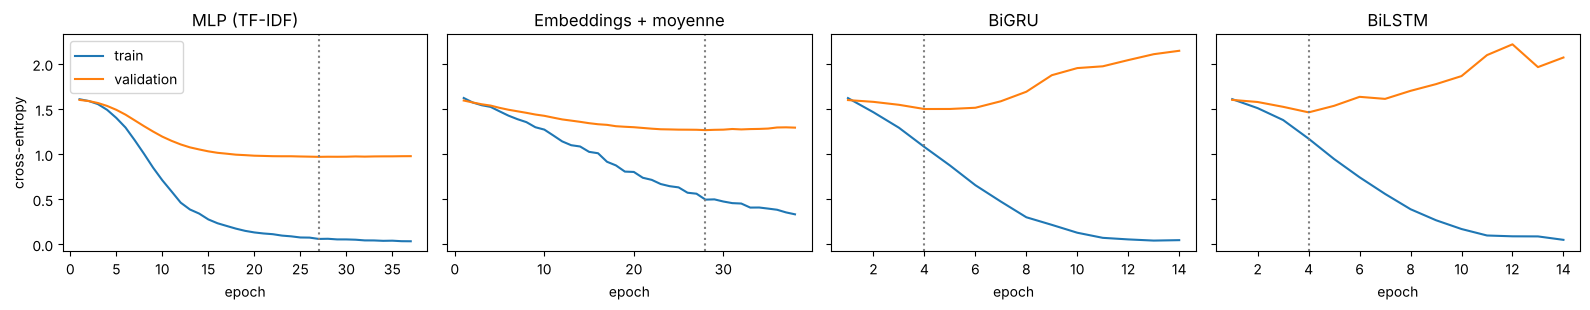

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, nom in zip(axes, NOMS_DL):
    h = historiques[nom]
    ax.plot(h["epoch"], h["loss_train"], label="train"); ax.plot(h["epoch"], h["loss_val"], label="validation")
    ax.axvline(h["loss_val"].idxmin() + 1, color="grey", ls=":"); ax.set_title(nom); ax.set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy"); axes[0].legend(); plt.tight_layout(); plt.show()

**Ce que montrent les courbes** (une graine, validation = 122 répliques) :

- **MLP (TF–IDF)** : la perte de validation baisse jusqu'à ≈ 1,0 puis **se stabilise** (arrêt vers l'epoch 27) alors que la perte d'entraînement continue de tomber vers 0 : surapprentissage modéré, contenu par le dropout et le weight decay.
- **Embeddings + moyenne** : même allure, plateau de validation plus haut (≈ 1,3).
- **BiGRU et BiLSTM** : la perte de validation atteint son minimum dès l'**epoch 4** (≈ 1,5, à comparer à ln 5 ≈ 1,61 pour un tirage uniforme) puis **remonte nettement** (≈ 2,1) pendant que la perte d'entraînement s'effondre : le réseau **mémorise** les 486 répliques d'entraînement. Le meilleur point de l'early stopping est un modèle à peine entraîné.

C'est le même phénomène que « sur-apprentissage » au TP 1 (train ≈ 100 %, test ≈ 66 %), en beaucoup plus marqué : plus un modèle est flexible (150 000 paramètres pour le BiGRU), plus il lui faut de données pour qu'elles le contraignent.

## 5. Évaluation

### 5.1 Tableau comparatif ML vs DL

Métrique principale : **F1 macro** (classes proches en effectifs mais on veut que chaque locuteur compte autant). L'écart-type porte sur les 5 graines (0 pour les modèles ML, déterministes). L'intervalle de confiance bootstrap mesure l'incertitude due à la **taille du test** (153 exemples).

In [11]:
def ligne(nom, preds_list):
    f1s = [f1_score(yte_i, p, average="macro") for p in preds_list]
    acc = [accuracy_score(yte_i, p) for p in preds_list]
    prec = [precision_score(yte_i, p, average="macro", zero_division=0) for p in preds_list]
    rap = [recall_score(yte_i, p, average="macro", zero_division=0) for p in preds_list]
    return {"modèle": nom, "accuracy": np.mean(acc), "précision (macro)": np.mean(prec), "rappel (macro)": np.mean(rap),
            "F1 macro": np.mean(f1s), "± (graines)": np.std(f1s)}

def bootstrap_ic(p, n=2000, seed=0):
    rng = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = rng.integers(0, len(yte_i), len(yte_i)); v.append(f1_score(yte_i[i], p[i], average="macro"))
    return np.percentile(v, [2.5, 97.5])

lignes = [ligne(n, [p]) for n, p in pred_ml.items()] + [ligne(n, list(preds_dl[n].values())) for n in NOMS_DL]
tab = pd.DataFrame(lignes).set_index("modèle")
ic = {n: bootstrap_ic(p) for n, p in pred_ml.items()} | {n: bootstrap_ic(preds_dl[n][SEEDS[0]]) for n in NOMS_DL}
tab["IC 95 % du F1 (bootstrap)"] = [f"[{ic[n][0]:.2f} ; {ic[n][1]:.2f}]" for n in tab.index]
display(tab.round(3))

,accuracy,précision (macro),rappel (macro),F1 macro,± (graines),IC 95 % du F1 (bootstrap)
modèle,,,,,,
Baseline (classe majoritaire),0.261,0.052,0.200,0.083,0.000,[0.07 ; 0.10]
ML · Naive Bayes,0.686,0.712,0.680,0.686,0.000,[0.61 ; 0.75]
ML · Régression logistique,0.660,0.670,0.662,0.663,0.000,[0.58 ; 0.74]
ML · LinearSVC,0.647,0.652,0.649,0.649,0.000,[0.57 ; 0.72]
MLP (TF-IDF),0.669,0.680,0.670,0.670,0.008,[0.58 ; 0.73]
Embeddings + moyenne,0.599,0.612,0.605,0.598,0.017,[0.50 ; 0.66]
BiGRU,0.373,0.376,0.380,0.367,0.041,[0.28 ; 0.43]
BiLSTM,0.379,0.384,0.384,0.374,0.032,[0.31 ; 0.46]


**Résultats (F1 macro, moyenne sur 5 graines pour les réseaux)**

| Modèle | F1 macro | Accuracy |
|---|---|---|
| Baseline (classe majoritaire) | 0,083 | 0,261 |
| ML · Naive Bayes | **0,686** | 0,686 |
| ML · Régression logistique | 0,663 | 0,660 |
| ML · LinearSVC | 0,649 | 0,647 |
| **MLP (TF–IDF)** | **0,670** ± 0,008 | 0,669 |
| Embeddings + moyenne | 0,598 ± 0,017 | 0,599 |
| BiGRU | 0,367 ± 0,041 | 0,373 |
| BiLSTM | 0,374 ± 0,032 | 0,379 |

**Ce qu'on peut affirmer :**

1. **Le deep learning ne bat pas le ML ici.** Le MLP (0,670) est au niveau de la régression logistique (0,663) et de Naive Bayes (0,686) : leurs intervalles de confiance à 95 % ([0,58 ; 0,73], [0,58 ; 0,74], [0,61 ; 0,75]) se **recouvrent presque entièrement**. Avec 153 exemples de test, on ne peut pas ordonner ces trois modèles.
2. **Les RNN faits maison sont nettement en dessous** (≈ 0,37, IC [0,28 ; 0,46]) : encore 4,5 fois le plancher (0,083), mais très loin des modèles TF–IDF.
3. **Les embeddings appris + moyenne (0,598) font moins bien que TF–IDF** : ils ne reçoivent ni bigrammes ni pondération IDF, et leurs vecteurs sont appris sur 608 exemples seulement.
4. **Pourquoi le DL ne gagne pas ici** (hypothèses cohérentes avec les mesures) : très peu de données (608 exemples), textes très courts (médiane 18 tokens), et un signal surtout **lexical** (noms, adresses, vocabulaire de la pièce : cf. TP 1) que le TF–IDF capture déjà bien. L'ordre des mots, que les RNN sont censés exploiter, apporte peu ici.
5. **Le coût n'est pas comparable.** Régression logistique : 17 325 coefficients, entraînement quasi instantané (non chronométré ici). MLP : 444 165 paramètres. BiGRU : 151 877 paramètres, environ 104 s pour 5 graines × 2 phases. Pour un gain nul.
6. **Les graines comptent.** Écart-type de 0,008 (MLP) à 0,041 (BiGRU) : rapporter un seul entraînement serait trompeur. À l'inverse, un écart-type de 0 pour les modèles ML (déterministes) **ne signifie pas absence d'incertitude** : l'intervalle bootstrap, qui vient de la taille du test, reste d'environ ± 0,07 pour tous.

### 5.2 Matrices de confusion : meilleur DL contre meilleur ML

Meilleur DL (F1 macro moyen) : MLP (TF-IDF) | meilleur ML : ML · Naive Bayes

                precision    recall  f1-score   support

DUKE VINCENTIO      0.629     0.667     0.647        33
    GLOUCESTER      0.659     0.675     0.667        40
      MENENIUS      0.655     0.760     0.704        25
     PETRUCHIO      0.773     0.630     0.694        27
         ROMEO      0.615     0.571     0.593        28

      accuracy                          0.660       153
     macro avg      0.666     0.661     0.661       153
  weighted avg      0.664     0.660     0.660       153



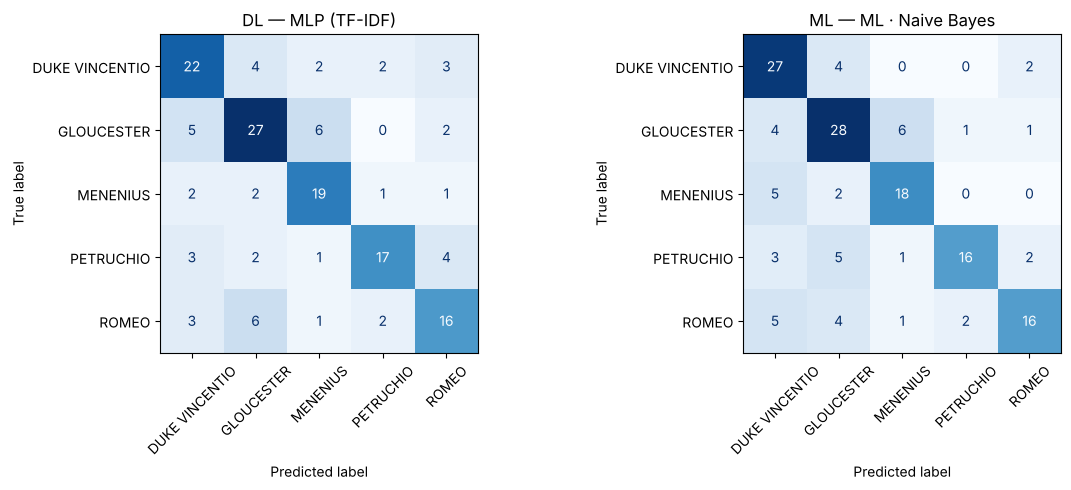

In [12]:
moy_dl = res_dl.groupby("modèle")["F1 macro"].mean()
meilleur_dl = moy_dl.idxmax()
meilleur_ml = max([n for n in pred_ml if n.startswith("ML")], key=lambda n: f1_score(yte_i, pred_ml[n], average="macro"))
print(f"Meilleur DL (F1 macro moyen) : {meilleur_dl} | meilleur ML : {meilleur_ml}\n")
p_dl = preds_dl[meilleur_dl][SEEDS[0]]
print(classification_report(yte_i, p_dl, target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (titre, p) in zip(axes, [(f"DL — {meilleur_dl}", p_dl), (f"ML — {meilleur_ml}", pred_ml[meilleur_ml])]):
    ConfusionMatrixDisplay.from_predictions(yte_i, p, display_labels=CLASSES, xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(titre)
plt.tight_layout(); plt.show()

**Lecture** (MLP à gauche, Naive Bayes à droite ; mêmes 153 répliques) :

- Les deux modèles font des erreurs **de même nature**. Dans les deux cas la confusion la plus fréquente est **GLOUCESTER pris pour MENENIUS (6 fois)**, et GLOUCESTER (classe la plus fréquente) agit comme « attracteur » : le MLP lui attribue 6 répliques de ROMEO, Naive Bayes 5 de PETRUCHIO.
- Par classe, le MLP est le plus à l'aise sur MENENIUS (F1 0,704) et PETRUCHIO (0,694, précision 0,77 mais rappel 0,63 : prudent) ; ROMEO est la plus difficile (F1 0,593, rappel 0,57).
- Ces cinq personnages viennent de **cinq pièces différentes** : les confusions ne s'expliquent donc pas par la proximité de pièce. Elles viennent surtout de répliques courtes et génériques (voir 5.4).
- Un changement d'architecture ne change pas la structure des erreurs : ce qui limite la performance, ce sont **les données et la tâche**, pas le modèle.

### 5.3 Courbe d'apprentissage : le DL a-t-il besoin de plus de données ?

On entraîne la régression logistique, le MLP et le BiGRU sur 25 %, 50 %, 75 % et 100 % du train (3 graines) et on mesure le F1 macro sur le même test.

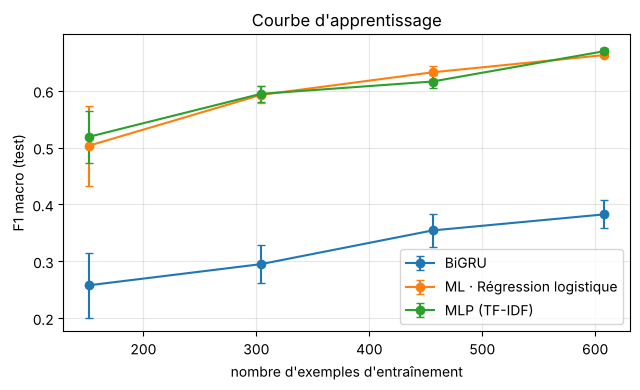

modèle,BiGRU,ML · Régression logistique,MLP (TF-IDF)
fraction,,,
0.25,0.258,0.504,0.519
0.50,0.295,0.593,0.595
0.75,0.354,0.633,0.616
1.00,0.383,0.663,0.670


In [13]:
# Courbe d'apprentissage : le DL a-t-il besoin de plus de données que le ML ?
# (nombre d'epochs fixé par les phases précédentes, 3 graines, sous-échantillonnage stratifié du train)
fractions = [0.25, 0.5, 0.75, 1.0]
ep_fixe = {n: int(np.median(epochs_opt[n])) for n in NOMS_DL}
lignes_ca = []
for frac in fractions:
    for s in SEEDS[:3]:
        if frac < 1:
            idx, _ = train_test_split(np.arange(len(X_train)), train_size=frac, stratify=ytr_i, random_state=s)
        else:
            idx = np.arange(len(X_train))
        Xs, ys = X_train[idx].reset_index(drop=True), ytr_i[idx]
        e = Encodeur().fit(Xs)
        lr_ = LogisticRegression(C=10, class_weight="balanced", max_iter=2000).fit(e.tfidf.transform(Xs), ys)
        lignes_ca.append({"fraction": frac, "modèle": "ML · Régression logistique", "graine": s,
                          "F1 macro": f1_score(yte_i, lr_.predict(e.tfidf.transform(X_test)), average="macro")})
        for nom in ["MLP (TF-IDF)", "BiGRU"]:
            m, _, _ = entrainer(nom, e, Xs.values, ys, s, n_epochs=ep_fixe[nom])
            Xt, Lt = entree(nom, e, X_test.values)
            lignes_ca.append({"fraction": frac, "modèle": nom, "graine": s,
                              "F1 macro": f1_score(yte_i, predire(m, Xt, Lt).argmax(1).numpy(), average="macro")})
ca = pd.DataFrame(lignes_ca).groupby(["modèle", "fraction"])["F1 macro"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(6.5, 4))
for nom, g in ca.groupby("modèle"):
    ax.errorbar(g["fraction"] * len(X_train), g["mean"], yerr=g["std"], marker="o", capsize=3, label=nom)
ax.set_xlabel("nombre d'exemples d'entraînement"); ax.set_ylabel("F1 macro (test)"); ax.set_title("Courbe d'apprentissage")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
display(ca.pivot(index="fraction", columns="modèle", values="mean").round(3))

**Lecture.** F1 macro de la régression logistique / du MLP / du BiGRU selon le nombre d'exemples d'entraînement :

| exemples | 152 | 304 | 456 | 608 |
|---|---|---|---|---|
| Régression logistique | 0,504 | 0,593 | 0,633 | 0,663 |
| MLP (TF–IDF) | 0,519 | 0,595 | 0,616 | 0,670 |
| BiGRU | 0,258 | 0,295 | 0,354 | 0,383 |

- **Aucune courbe n'a atteint son plateau** à 608 exemples : toutes montent encore. Plus de données améliorerait les trois modèles ; on ne peut pas conclure sur ce que vaudrait chaque modèle avec 10 fois plus d'exemples.
- **LR et MLP restent superposés** à toutes les tailles : le MLP n'a pas d'avantage, même quand il a plus de données relatives.
- Le **BiGRU progresse aussi** (+0,13 de F1 entre 25 % et 100 %) mais **pas plus vite** que la régression logistique (+0,16) : l'écart (≈ 0,28) ne se résorbe pas dans cette plage. Dire qu'il le ferait avec beaucoup plus de données serait de la spéculation : **c'est une hypothèse, pas un résultat**.
- Les barres d'erreur (3 graines) sont étroites par rapport à l'écart entre le BiGRU et les deux autres : cet écart est réel, pas un accident de graine.

### 5.4 Analyse des erreurs : les modèles se trompent-ils sur les mêmes répliques ?

In [14]:
# Les modèles se trompent-ils sur les mêmes répliques ?
ok = {n: (p == yte_i) for n, p in pred_ml.items() if n.startswith("ML")}
ok.update({n: (preds_dl[n][SEEDS[0]] == yte_i) for n in NOMS_DL})
M = pd.DataFrame(ok)
print(f"Répliques que TOUS les modèles ratent : {(~M.any(axis=1)).sum()} / {len(M)} ({(~M.any(axis=1)).mean():.1%})")
print(f"Répliques que TOUS les modèles réussissent : {M.all(axis=1).sum()} / {len(M)} ({M.all(axis=1).mean():.1%})")
print(f"Plafond « oracle » (au moins un modèle a juste) : {M.any(axis=1).mean():.1%}")

a, b = "ML · Régression logistique", meilleur_dl
print(f"\n{a} vs {b} : seul {a} juste = {(M[a] & ~M[b]).sum()}, seul {b} juste = {(~M[a] & M[b]).sum()}, "
      f"tous deux justes = {(M[a] & M[b]).sum()}, tous deux faux = {(~M[a] & ~M[b]).sum()}")

nb = X_test.str.split().str.len()
bins = pd.cut(nb, [4, 10, 25, 10_000], labels=["5-10 mots", "10-25 mots", "25+ mots"])
print("\nAccuracy selon la longueur de la réplique :")
display(M.groupby(bins).mean().round(2).assign(n=bins.value_counts().sort_index()))

Répliques que TOUS les modèles ratent : 28 / 153 (18.3%)
Répliques que TOUS les modèles réussissent : 33 / 153 (21.6%)
Plafond « oracle » (au moins un modèle a juste) : 81.7%

ML · Régression logistique vs MLP (TF-IDF) : seul ML · Régression logistique juste = 6, seul MLP (TF-IDF) juste = 6, tous deux justes = 95, tous deux faux = 46

Accuracy selon la longueur de la réplique :


,ML · Naive Bayes,ML · Régression logistique,ML · LinearSVC,MLP (TF-IDF),Embeddings + moyenne,BiGRU,BiLSTM,n
replique,,,,,,,,
5-10 mots,0.55,0.53,0.49,0.51,0.43,0.27,0.35,51
10-25 mots,0.72,0.74,0.72,0.66,0.68,0.42,0.46,50
25+ mots,0.79,0.71,0.73,0.81,0.63,0.40,0.38,52


**Lecture.**

- **18,3 % des répliques (28/153) sont ratées par les 7 modèles**, et seulement 21,6 % (33/153) sont réussies par tous. Au moins un modèle a juste sur 81,7 % des répliques : un plafond « oracle » qu'aucun modèle seul n'approche (il inclut les RNN, faibles, donc il est généreux).
- **LR et MLP sont presque interchangeables** : 95 répliques justes pour les deux, 46 fausses pour les deux, et seulement 12 sur lesquelles ils divergent (6 de chaque côté). Le MLP n'apprend pas quelque chose de **différent** de la régression logistique : il commet les mêmes erreurs.
- **La longueur de la réplique est le facteur dominant**, pour *tous* les modèles. Accuracy sur 5-10 / 10-25 / 25+ mots : Naive Bayes 0,55 / 0,72 / 0,79 ; MLP 0,51 / 0,66 / 0,81 ; BiGRU 0,27 / 0,42 / 0,40. Sous 10 mots, un humain non plus ne saurait pas répondre : c'est un **plafond de la tâche**, pas du modèle (même constat qu'au TP 1).
- Le BiGRU est mauvais **à toutes les longueurs** : il progresse entre 5-10 et 10-25 mots (0,27 → 0,42) puis stagne (0,40), alors que les modèles TF–IDF continuent de monter (MLP 0,81 sur 25+ mots).

### 5.5 Le DL apprend-il la pièce ou le personnage ? (retour sur le TP 1)

Même test que le TP 1 : on masque les noms propres (et autres mots toujours vus en majuscule) dans train **et** test, on réentraîne, et on regarde la chute du score.

In [15]:
# Même test qu'au TP 1 : le DL s'appuie-t-il lui aussi sur les noms propres (donc sur la pièce) ?
minuscules = set(re.findall(r"\b[a-z]{3,}\b", texte))
noms = {m.lower() for m in re.findall(r"\b[A-Z][a-z]{2,}\b", texte)} - minuscules      # mots toujours vus en majuscule
motif = re.compile(r"\b(" + "|".join(sorted(map(re.escape, noms))) + r")\b", flags=re.IGNORECASE)
masque = lambda s: s.map(lambda t: motif.sub(" ", t))
Xtr_m, Xte_m = masque(X_train), masque(X_test)
print(f"{len(noms)} termes masqués (mots capitalisés jamais vus en minuscule dans le corpus)")

e_m = Encodeur().fit(Xtr_m)
lignes_m = []
lr_m = LogisticRegression(C=10, class_weight="balanced", max_iter=2000).fit(e_m.tfidf.transform(Xtr_m), ytr_i)
nb_m = MultinomialNB(alpha=0.1).fit(e_m.tfidf.transform(Xtr_m), ytr_i)
for nom, mod in [("ML · Régression logistique", lr_m), ("ML · Naive Bayes", nb_m)]:
    p = mod.predict(e_m.tfidf.transform(Xte_m))
    lignes_m.append({"modèle": nom, "F1 sans masquage": tab.loc[nom, "F1 macro"], "F1 avec noms masqués": f1_score(yte_i, p, average="macro")})
for nom in NOMS_DL:
    f = []
    for s in SEEDS[:3]:
        m, _, _ = entrainer(nom, e_m, Xtr_m.values, ytr_i, s, n_epochs=ep_fixe[nom])
        Xt, Lt = entree(nom, e_m, Xte_m.values)
        f.append(f1_score(yte_i, predire(m, Xt, Lt).argmax(1).numpy(), average="macro"))
    lignes_m.append({"modèle": nom, "F1 sans masquage": tab.loc[nom, "F1 macro"], "F1 avec noms masqués": np.mean(f)})
mq = pd.DataFrame(lignes_m).set_index("modèle")
mq["variation"] = mq["F1 avec noms masqués"] - mq["F1 sans masquage"]
display(mq.round(3))

896 termes masqués (mots capitalisés jamais vus en minuscule dans le corpus)


,F1 sans masquage,F1 avec noms masqués,variation
modèle,,,
ML · Régression logistique,0.663,0.620,-0.043
ML · Naive Bayes,0.686,0.634,-0.052
MLP (TF-IDF),0.670,0.616,-0.055
Embeddings + moyenne,0.598,0.565,-0.033
BiGRU,0.367,0.348,-0.019
BiLSTM,0.374,0.377,0.003


**Lecture.** Variation du F1 macro quand on masque les 896 mots toujours vus en majuscule dans le corpus (noms de personnages et de lieux) dans le train **et** le test :

| Modèle | sans masquage | noms masqués | variation |
|---|---|---|---|
| Régression logistique | 0,663 | 0,620 | −0,043 |
| Naive Bayes | 0,686 | 0,634 | −0,052 |
| MLP (TF–IDF) | 0,670 | 0,616 | −0,055 |
| Embeddings + moyenne | 0,598 | 0,565 | −0,033 |
| BiGRU | 0,367 | 0,348 | −0,019 |
| BiLSTM | 0,374 | 0,377 | +0,003 |

- **Les modèles TF–IDF (ML ou DL) perdent tous 4 à 5 points** : le **MLP s'appuie sur les noms propres autant que la régression logistique**. Le raccourci « on reconnaît la pièce » n'est pas propre au ML classique ; un réseau de neurones le prend aussi, parce que c'est dans les données.
- La chute est **modérée** : 6 à 8 % de perte relative, avec des scores restant très supérieurs à la baseline (0,083). Le signal ne se réduit pas aux noms propres : il reste du vocabulaire propre à chaque pièce (`king`, `kill`, `tribunes`, `love`, `night`…) qui n'est pas masqué, donc le masquage **ne prouve pas** que le modèle ait appris le style ; il montre seulement qu'une partie visible du raccourci n'explique pas tout.
- Pour BiGRU et BiLSTM, les variations (−0,019 et +0,003) sont **dans le bruit** (écart-type des graines 0,03 à 0,04) : leurs scores sont trop bas pour en tirer une conclusion.
- Précaution : le détecteur de noms est une heuristique (mots jamais vus en minuscule dans le corpus) ; il peut masquer quelques mots communs et en rater certains. Le chiffre est un ordre de grandeur.

## 6. Conclusions

**Messages à retenir**

1. **Le deep learning n'a pas battu le ML sur cette tâche.** MLP (0,670), régression logistique (0,663) et Naive Bayes (0,686) sont indiscernables avec 153 exemples de test ; les RNN entraînés de zéro sont très en dessous (≈ 0,37). Un réseau plus gros ne vaut pas mieux : il est surtout plus cher.
2. **Le régime de données explique le résultat.** 608 exemples de 18 tokens en médiane : c'est le terrain des modèles linéaires sur TF–IDF. Les courbes d'apprentissage montent encore, donc plus de données aideraient probablement tout le monde ; on ne peut pas prédire si les courbes se rapprocheraient (hypothèse non testée).
3. **Mesurer un réseau demande plus de rigueur que mesurer un modèle linéaire** : jeu de validation pour l'arrêt, plusieurs graines (±0,04 pour le BiGRU), intervalle de confiance sur le test. Sans cela, un seul entraînement de BiGRU aurait pu donner un score décalé de plusieurs points (écart-type 0,04) selon la graine.
4. **Les modèles apprennent le même raccourci.** Masquer les noms propres coûte 4 à 5 points aussi bien au MLP qu'à la régression logistique : la pièce reste une grande partie du signal, quelle que soit l'architecture. Une métrique correcte ne dit pas ce que le modèle a appris.
5. **Le plafond vient aussi de la tâche** : 18 % des répliques sont ratées par tous les modèles et les répliques de moins de 10 mots sont difficiles pour tous.

**Limites de ce TP** (à garder en tête) : un seul découpage train/test de petite taille ; hyperparamètres réglés grossièrement ; **pas d'embeddings pré-entraînés** (ils n'étaient pas téléchargeables dans mon environnement : c'est la piste naturelle pour les RNN, avec des vecteurs type GloVe ou fastText) ; le détecteur de noms propres est une heuristique.

**Transition vers le TP 3 et le cours suivant.** Ce qui manque aux réseaux de ce TP, c'est un **pré-entraînement** : des représentations apprises sur d'énormes corpus avant de voir nos 608 répliques. C'est ce que fournissent les modèles de langage, et ce que le TP 3 exploite sans aucun entraînement, par le seul **prompting**.